# Explore precedence and capacity in a feasible frontier

**Question:** How do precedence and two-resource capacity shape the actions available to a schedule builder?

**Level:** 2 : Method in practice.

## Objectives

Follow one generated block graph from its seeded source through admissible actions to an independently checked schedule. By the end, you can explain why a precedence frontier alone is insufficient, inspect the two resource limits separately, and distinguish a complete horizon from a deliberate early stop. This is an implementation notebook: the calls below import the same product modules used by the planned offline runner. The generated values are synthetic method-development data. They are not MineLib observations, a trained result, or an operating plan. The seed, graph family, feature order and resource units remain visible so another reader can reproduce every displayed count.

## Setup

The environment needs the repository's pinned NumPy and OreBlocks dependency plus Matplotlib for figures. No model weights are loaded and no training occurs in this experiment. The 0.11 bake remains the measured baseline. No 0.12 product bake is committed yet. This notebook isolates the deterministic decoder on synthetic method-development data and does not train, load or evaluate learned weights. Keeping those stages separate prevents a demonstration graph from being mistaken for a product benchmark case. All code is deterministic for a fixed generator version, family, size and seed. If a dependency or source file is unavailable, execution should stop at setup rather than silently substitute a different implementation.

The exact pins are `oreblocks==0.6.6`, `numpy==2.5.1` and `matplotlib==3.11.2`.

```bash
python -m pip install oreblocks==0.6.6 numpy==2.5.1 matplotlib==3.11.2
```

Print exact installed versions before importing the method.

In [1]:
# Confirm exact versions before loading product modules.
import importlib.metadata as metadata
print({name: metadata.version(name) for name in ('oreblocks', 'numpy', 'matplotlib')})

{'oreblocks': '0.6.6', 'numpy': '2.5.1', 'matplotlib': '3.11.2'}


## Data

A graph has a canonical integer index for every block, a directed acyclic predecessor relation, a discounted economic value, two resource consumptions and a capacity vector for each period. The four generator families alter dependency geometry while retaining the same explicit data contract. Here we select the crosscut family, whose nodes can depend on both a previous bench-like row and a neighboring block. Edge thinning is seeded, so graph structure is repeatable. Node features are named and ordered by the generator. They contain value, tonnage, processing share, grade, depth and local graph degrees; identifiers, split labels and outcomes are absent.

Generate one crosscut graph from the declared seed and inspect its source receipt and feature matrix.

In [2]:
# Generate one reproducible graph and inspect its source contract.
# Locate the repository root from the notebook's working directory.
from pathlib import Path
import sys
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / 'data-pipeline').is_dir())
sys.path.insert(0, str(ROOT / 'data-pipeline'))
from pipeline.model.frontier_data import generate_graph, FEATURE_NAMES
SEED, FAMILY, SIZE = 4217, 'crosscut', 96
graph = generate_graph(SEED, FAMILY, SIZE, periods=8)
instance = graph.instance
print({'generator': graph.family_parameters, 'seed': graph.seed})
print({'blocks': len(instance.values), 'arcs': sum(map(len, instance.predecessors))})
print({'feature_names': FEATURE_NAMES, 'feature_shape': graph.node_features.shape})
if not np.isfinite(graph.node_features).all():
    raise ValueError('the generator emitted non-finite feature values')

{'generator': 'frontier-graphs/1.0.0:crosscut:size=96:periods=8:v1', 'seed': 4217}
{'blocks': 96, 'arcs': 180}
{'feature_names': ('value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count'), 'feature_shape': (96, 7)}


## Method

At a decision state, eligibility requires that every immediate predecessor has already been scheduled no later than the current period. The resource mask then removes any eligible block that would exceed at least one residual limit. A block can therefore be precedence-ready yet inadmissible for capacity. The environment adds explicit stop-period and stop-schedule actions, so a policy can reserve a period or return a valid partial plan. This notebook uses a transparent deterministic score only to inspect transitions. That score is not a learned policy and its output cannot be described as a training or evaluation result.

At period \(t\), block \(b\) is precedence-ready only when it is unassigned and every predecessor has already been assigned to a period no later than \(t\). Let \(P_b\) be its predecessor set and \(A_t\) the assignments made to period \(t\).

$$
E_t=\{b\notin A \colon P_b\subseteq\{i:p_i\leq t\}\}.
$$

$$
F_t=\{b\in E_t \colon r_{bk}\leq C_{tk}-\sum_{i\in A_t}r_{ik}\;\forall k\}.
$$

The first set enforces graph order; the second checks the entire resource vector against remaining period capacity. A block outside \(F_t\) may still be useful later, so removing it from the current action set does not discard it from the instance. Stop-period advances the clock without assigning another block, while stop-schedule returns the current feasible partial plan. These explicit actions make unused capacity and incomplete coverage visible rather than hiding them in an invalid assignment.

Import the product functions, then compare precedence eligibility with both resource limits.

In [3]:
# Import the product frontier and validator functions.
from pipeline.model.frontier_policy import (
    feasible_frontier, precedence_frontier, replay_frontier_policy, validate_schedule,
)
ready = precedence_frontier(instance, (), 0)
feasible = feasible_frontier(instance, (), 0)
print({'period': 0, 'precedence_ready': len(ready)})
print({'resource_feasible': len(feasible), 'removed_by_capacity': len(ready) - len(feasible)})
print({'ready_indices': ready[:12], 'feasible_indices': feasible[:12]})

{'period': 0, 'precedence_ready': 1}
{'resource_feasible': 1, 'removed_by_capacity': 0}
{'ready_indices': (0,), 'feasible_indices': (0,)}


Replay a transparent score to expose successive policy states. It is a mechanics example, not a learned result.

In [4]:
# Replay value per mining unit as an illustrative deterministic score.
def illustrative_score(block, period, assigned):
    if block < 0:
        return -1e6
    return float(instance.values[block] / max(instance.resources[block, 0], 1e-12))

result = replay_frontier_policy(instance, illustrative_score, tonnage=graph.tonnage)
ready_counts, feasible_counts, prefix = [], [], []
for assignment in result.assignments:
    ready_counts.append(len(precedence_frontier(instance, prefix, assignment.period)))
    feasible_counts.append(len(feasible_frontier(instance, prefix, assignment.period)))
    prefix.append(assignment)
print({'assignments': len(result.assignments), 'stopped': result.stopped})
print({'npv': round(result.npv, 4), 'tonnage_coverage': round(result.tonnage_coverage, 4)})
print({'positive_value_coverage': round(result.positive_value_coverage, 4)})

{'assignments': 87, 'stopped': 'horizon-complete'}
{'npv': -62.1729, 'tonnage_coverage': 0.9134}
{'positive_value_coverage': 0.8055}


Recompute the objective from the original instance and verify each chosen block against its prior feasible frontier.

In [5]:
# Independently recompute the exported objective from source arrays.
independent_npv = validate_schedule(instance, result.assignments)
print({'independent_npv': round(independent_npv, 4)})
print({'objective_matches': bool(np.isclose(independent_npv, result.npv))})

{'independent_npv': -62.1729}
{'objective_matches': True}


Check each assignment against its prior state mask; this probes the transition path, not just final totals.

In [6]:
# Rebuild each prefix and prove every selected block was admissible.
prefix = []
admissible = []
for assignment in result.assignments:
    admissible.append(assignment.block in feasible_frontier(instance, prefix, assignment.period))
    prefix.append(assignment)
print({'admissible_assignments': sum(admissible), 'schedule_assignments': len(result.assignments)})

{'admissible_assignments': 87, 'schedule_assignments': 87}


### Diagnostic walk-through

The first plot compares the precedence-ready count with the smaller resource-feasible action count at each period boundary. A gap between the lines means that capacity, rather than precedence, removed choices. The second plot shows the selected block values alongside the resulting schedule's per-period resource load. These views answer different questions: one diagnoses the action mask, while the other checks how decisions consume the declared budget. They are derived directly from the generated instance and the validated schedule; no values are copied from a manuscript or typed into a chart.

Plot precedence-ready and resource-feasible choices at each selected decision.

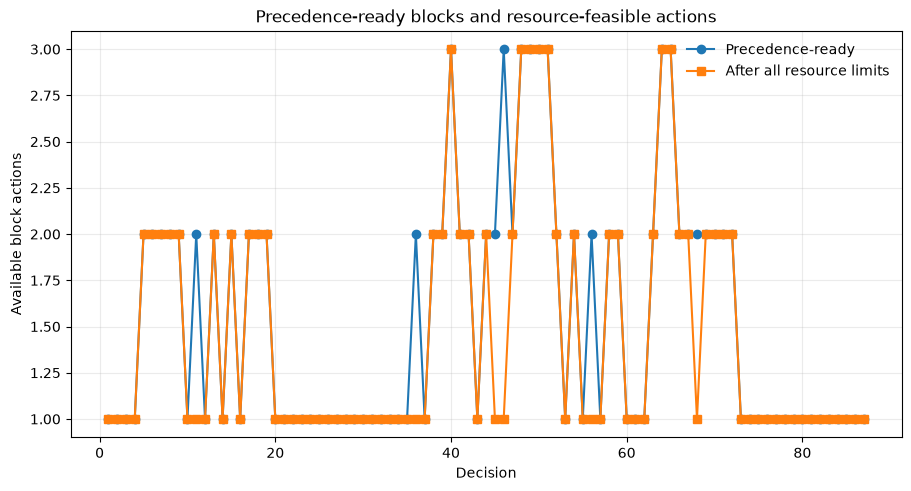

In [7]:
# Plot the number of eligible actions before and after resource filtering.
fig, ax = plt.subplots(figsize=(9, 4.8), constrained_layout=True)
decisions = np.arange(1, len(ready_counts) + 1)
ax.plot(decisions, ready_counts, marker='o', label='Precedence-ready')
ax.plot(decisions, feasible_counts, marker='s', label='After all resource limits')
ax.set_title('Precedence-ready blocks and resource-feasible actions')
ax.set_xlabel('Decision')
ax.set_ylabel('Available block actions')
ax.grid(alpha=.25)
ax.legend(frameon=False)
plt.show()

### Example trace

The evidence here is intentionally bounded. We report the generator receipt, node-feature shape, frontier counts, schedule length, objective recomputed by the independent validator, tonnage coverage, value coverage and stop reason. The validation call recomputes uniqueness, precedence, period capacity and discounted objective from the exported assignments. Passing that check establishes feasibility of this one generated schedule. It does not measure generalization, compare against another scheduling method, establish a benefit, or evaluate any of the thirteen product cases. Those questions require the frozen test protocol and a completed all-case bake.

Compare selected signed values with mining use and the period limit; those axes have different units.

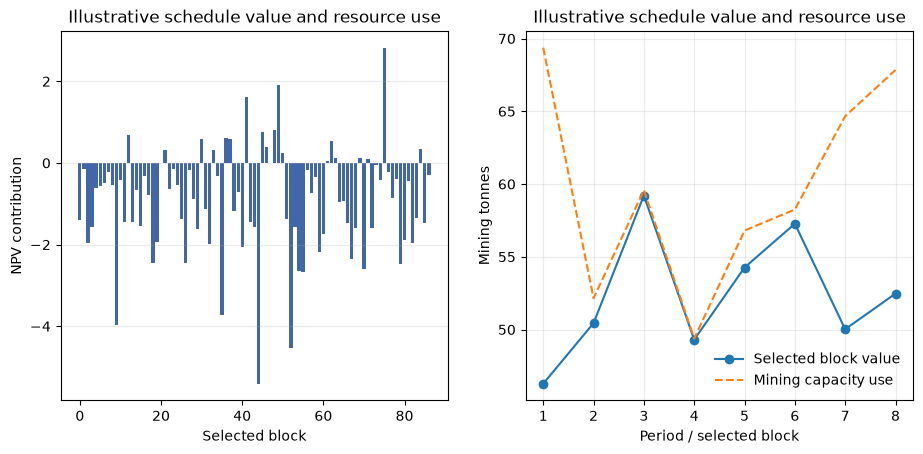

{'mining_use_by_period': [46.28, 50.44, 59.21, 49.3, 54.26, 57.27, 50.02, 52.47]}
{'mining_limit_by_period': [69.37, 52.15, 59.58, 49.38, 56.8, 58.25, 64.66, 67.84]}


In [8]:
# Compare signed selected values with mining use and the declared limits.
period_use = np.zeros((len(instance.capacities), instance.resources.shape[1]))
for assignment in result.assignments:
    period_use[assignment.period] += instance.resources[assignment.block]
selected_values = [instance.values[a.block] for a in result.assignments]
fig, (value_ax, resource_ax) = plt.subplots(1, 2, figsize=(11, 4.8))
value_ax.bar(np.arange(len(selected_values)), selected_values, color='#4267a9')
value_ax.set_title('Illustrative schedule value and resource use')
value_ax.set_xlabel('Selected block')
value_ax.set_ylabel('NPV contribution')
periods = np.arange(1, len(instance.capacities) + 1)
resource_ax.plot(periods, period_use[:, 0], marker='o', label='Selected block value')
resource_ax.plot(periods, instance.capacities[:, 0], linestyle='--', label='Mining capacity use')
resource_ax.set_title('Illustrative schedule value and resource use')
resource_ax.set_xlabel('Period / selected block')
resource_ax.set_ylabel('Mining tonnes')
resource_ax.grid(alpha=.25)
resource_ax.legend(frameon=False)
value_ax.grid(axis='y', alpha=.25)
plt.show()
print(dict(mining_use_by_period=np.round(period_use[:, 0], 2).tolist()))
print(dict(mining_limit_by_period=np.round(instance.capacities[:, 0], 2).tolist()))

The mask can remove a block only after checking all resource dimensions. If the two curves differ, inspect the residual capacity vector before attributing that difference to graph structure. The plot is a state diagnostic, not a performance comparison. The validator result below applies to this schedule and seed alone; it gives no estimate of performance on an unseen graph.

### Sensitivity and limits

We vary all declared period capacities by the same multiplier while keeping the seeded graph, values, resource use and precedence edges fixed. The precedence-ready set at period zero should remain unchanged because graph order does not depend on capacity. The feasible action set may shrink as the limits tighten, and it may match the ready set once all eligible blocks fit. This contrast checks the mechanism that the policy will later rely on, not the quality of a learned score.

The factor sweep uses 0.65, 0.82 and 1.00 times the declared capacity vector. It is not a sensitivity analysis of mine capacity in physical units: the generator has two resource dimensions and the values are synthetic. A blocked action can be reconsidered in a later period, but if total capacity across the horizon is inadequate the final schedule may remain partial. The coverage fractions therefore belong beside the objective. The explicit validator is still required after replay because a correct mask at each step does not prove that an exported list was not modified or reordered.

capacity scale=0.65: ready=1; feasible=1
capacity scale=0.82: ready=1; feasible=1
capacity scale=1.00: ready=1; feasible=1


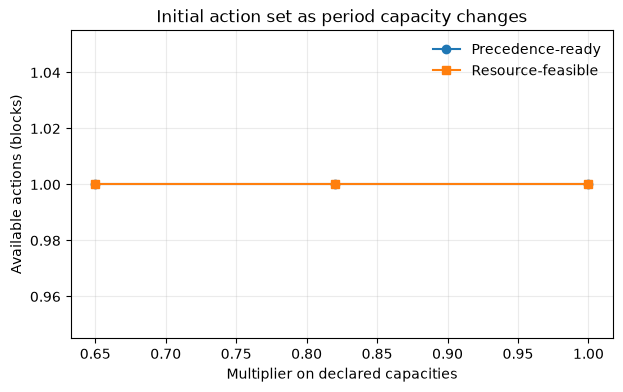

In [9]:
# Compare precedence and capacity action counts under common capacity scaling.
from dataclasses import replace
capacity_scales = [0.65, 0.82, 1.00]
ready_by_scale, feasible_by_scale = [], []
for scale in capacity_scales:
    scaled_instance = replace(instance, capacities=instance.capacities * scale)
    ready_by_scale.append(len(precedence_frontier(scaled_instance, (), 0)))
    feasible_by_scale.append(len(feasible_frontier(scaled_instance, (), 0)))
    print(f'capacity scale={scale:.2f}: ready={ready_by_scale[-1]}; '
          f'feasible={feasible_by_scale[-1]}')
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(capacity_scales, ready_by_scale, marker='o', label='Precedence-ready')
ax.plot(capacity_scales, feasible_by_scale, marker='s', label='Resource-feasible')
ax.set(title='Initial action set as period capacity changes',
       xlabel='Multiplier on declared capacities', ylabel='Available actions (blocks)')
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.show()

The two curves separate structural eligibility from the resource filter. The ready count is constant across this multiplier because the graph does not change; the feasible count responds to both capacity dimensions. If a period has no feasible block, an explicit stop action can still advance the policy to a later period. The plot does not show training, out-of-family transfer or objective quality, and a larger feasible frontier is not automatically a better decision.

### Use the frontier contract with your own data

Create a `FrontierInstance` from a stable block order. Its value vector has one finite value per block; `resources` is a block-by-resource matrix with non-negative use; `predecessors` contains the immediate prerequisite indices; `capacities` is period-by-resource; and `discount_rate` defines the objective. Confirm that predecessor indices point from prerequisite to dependent block and that the graph is acyclic. Each resource column must use the same unit in block consumption and period capacity. Keep tonnage separately if reporting tonnage coverage; resource use is not necessarily tonnage.

At each decision, pass the existing assignments and period to `precedence_frontier` and `feasible_frontier`. The second result is an admissible subset, not a ranking. A policy score may rank only those returned block actions, plus the explicit stop actions. Replay the selected sequence through the product environment, export the assignments, and call `validate_schedule` against the original instance. Check the independently recomputed discounted value and both coverage fractions; retain stop reason and rejected-action counts. Do not trust a policy's own action mask as the export validator.

For raw block models, preserve source IDs separately from canonical indices and write a reversible index map. Record which rows were filtered and why. If a source field is unavailable, reject or explicitly adapt the contract; do not silently fill grade or a resource with a constant. The generated crosscut graph demonstrates the interface only. A production policy additionally requires a frozen train-only normalizer, graph-family-disjoint splits, checkpoint provenance and independent held-out evaluation.

The generator's crosscut family has two classes of incoming edges: a row dependency and a lateral dependency. This lets a reader see that frontier eligibility is a graph property rather than a simple coordinate sort. The capacity filter is independent: it reads the full resource vector for each candidate, including the processing dimension, before exposing the action. Changing the score used by the replay cannot bypass that filter, because the environment chooses only from the returned admissible actions. This is the intended extension seam for a learned policy, but this mechanics lesson does not train or validate one.

A useful review also asks whether an action was excluded for the correct reason. For each step, compare the current assignment list, remaining resource vector and predecessor periods with the candidates returned by the two frontier calls. If a candidate disappears only after resource filtering, identify which resource is binding; if it is absent earlier, inspect its predecessor assignments. This hand-check on selected states complements the automated independent validator and helps a developer debug contract mistakes without treating every empty frontier as a solver failure.

## Results

Use the printed table and figures together. A low feasible-action count is not itself a policy defect; it can be the correct consequence of a binding resource. A partial schedule can be feasible while leaving positive-value blocks and tonnage unmined, which is why coverage is reported in two separate units. The selected demonstration score favors positive value per unit of mining capacity, but it is deliberately simple and has no claim to optimize the multi-period objective. Interpret the output as a worked example of the data path and validator, not as evidence that one score is preferable. **Answer:** In this 96-block example, precedence and capacity create distinct action sets, and the independent schedule check confirms the exported objective.

## Summary

You have traced a seeded graph into a mask, advanced periods with explicit stop actions, and checked the final assignments independently. The key invariant is that the exported schedule is validated from the original instance rather than trusted because the environment previously exposed a mask. The separate training pipeline now records a train-only normalizer, disjoint split receipt, checkpoint hash and per-member budget under external roots. This decoder lesson does not run that pipeline or support claims about learned-policy performance. Product rendering will consume committed, validated traces; the browser will not run PPO or load training weights. A separate empirical lesson will be grounded in the frozen training receipt and held-out evaluation after those artifacts are complete; this decoder lesson is not a substitute for those results. The example is intentionally small enough to audit block by block, but the same independent checks apply at the declared synthetic graph sizes. A successful example is a software check, not statistical evidence. Keep that distinction when adapting the workflow: first freeze the data contract, then run the held-out experiment, and finally report every failed, partial and complete case without selective filtering.

## References

The graph-policy pattern is informed by resource-constrained project scheduling research, where a policy ranks currently eligible tasks and a schedule-generation procedure enforces feasibility. The transfer boundary matters: those papers optimize different objectives and do not establish PhaseFlow performance. The source below is included for method context only. The implementation shown here is the approved PhaseFlow design under development, and every numerical output in this notebook is generated from the stated synthetic seed rather than taken from that publication. Huang and Ontañón (2022) show that a state-dependent invalid-action mask can define a valid policy-gradient distribution, and test masking in μRTS; their results support studying masked sampling, but they do not establish feasibility or performance for open-pit scheduling.

[Teichteil-Königsbuch et al., ICAPS 2023](https://doi.org/10.1609/icaps.v33i1.27244).
- Resource-constrained scheduling policy with graph neural networks, ICAPS 2023: https://doi.org/10.1609/icaps.v33i1.27244
- OreBlocks scheduling package: https://pypi.org/project/oreblocks/
- MineLib open-pit scheduling problem library: https://doi.org/10.1007/s10479-012-1258-3
- Huang, S., & Ontañón, S. (2022). A closer look at invalid action masking in policy gradient algorithms. The International FLAIRS Conference Proceedings, 35. https://doi.org/10.32473/flairs.v35i.130584
